# 13% — MenuDemand Forecast — FULL MASTER v2

Corrected final notebook for next-day menu-item demand forecasting.

Operational champion is selected ONLY by validation MAE across both baselines and learned models.

- Granularity: Product × Day
- Target: units sold
- Forecast protocol: rolling one-day-ahead
- Train: through 2025-07-31
- Validation: 2025-08-01 → 2025-08-31
- Test: 2025-09-01 → 2025-09-30
- Metrics: MAE, RMSE, WAPE, Bias

The notebook distinguishes:
- Operational Champion = best overall validation candidate
- Best Learned Model = best LightGBM candidate

In [1]:
import os, sys, time
print("=== MENUDEMAND FORECAST 13% — FULL MASTER v2 BOOT ===", flush=True)
print("[BOOT] Python:", sys.version, flush=True)
print("[BOOT] cwd:", os.getcwd(), flush=True)
print("[BOOT] heartbeat 1", flush=True)
time.sleep(1)
print("[BOOT] heartbeat 2", flush=True)
with open("/kaggle/working/MENUDEMAND_13PCT_V2_STARTED.txt", "w", encoding="utf-8") as f:
    f.write("started\n")
print("=== HEARTBEAT OK ===", flush=True)

=== MENUDEMAND FORECAST 13% — FULL MASTER v2 BOOT ===
[BOOT] Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
[BOOT] cwd: /kaggle/working
[BOOT] heartbeat 1
[BOOT] heartbeat 2
=== HEARTBEAT OK ===


## 1. Environment and paths

In [2]:
import importlib.util, subprocess
need = []
if importlib.util.find_spec("lightgbm") is None: need.append("lightgbm")
if importlib.util.find_spec("sklearn") is None: need.append("scikit-learn")
if importlib.util.find_spec("joblib") is None: need.append("joblib")
if need:
    print("[SETUP] Installing:", need, flush=True)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need])
print("[SETUP] dependencies OK", flush=True)

[SETUP] dependencies OK


In [3]:
from pathlib import Path
import json, random, shutil, warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_ROOT = Path("/kaggle/input/datasets/loliwibu/anonymous-transactional-dataset/Anonymous Transactional Dataset")
TX_PATH = DATA_ROOT / "Transactions.csv"
PRODUCT_PATH = DATA_ROOT / "Products.csv"

if not TX_PATH.exists() or not PRODUCT_PATH.exists():
    tx_candidates = list(Path("/kaggle/input").rglob("Transactions.csv"))
    product_candidates = list(Path("/kaggle/input").rglob("Products.csv"))
    if not tx_candidates or not product_candidates:
        raise FileNotFoundError("Transactions.csv / Products.csv not found")
    TX_PATH = tx_candidates[0]
    PRODUCT_PATH = product_candidates[0]
    DATA_ROOT = TX_PATH.parent

WORK = Path("/kaggle/working/menudemand_13pct_v2")
REPORTS = WORK / "reports"
MODELS = WORK / "models"
ASSET_DATA = WORK / "assets" / "dataset"
ASSET_TRAIN = WORK / "assets" / "training"
ASSET_EVAL = WORK / "assets" / "evaluation"
ASSET_PRED = WORK / "assets" / "predictions"

for p in [WORK, REPORTS, MODELS, ASSET_DATA, ASSET_TRAIN, ASSET_EVAL, ASSET_PRED]:
    p.mkdir(parents=True, exist_ok=True)

print("[PATH]", DATA_ROOT)
print("[PATH]", TX_PATH)
print("[PATH]", PRODUCT_PATH)
assert TX_PATH.exists() and PRODUCT_PATH.exists()
print("=== INPUT CHECK PASSED ===", flush=True)

[PATH] /kaggle/input/datasets/loliwibu/anonymous-transactional-dataset/Anonymous Transactional Dataset
[PATH] /kaggle/input/datasets/loliwibu/anonymous-transactional-dataset/Anonymous Transactional Dataset/Transactions.csv
[PATH] /kaggle/input/datasets/loliwibu/anonymous-transactional-dataset/Anonymous Transactional Dataset/Products.csv
=== INPUT CHECK PASSED ===


## 2. Load and raw audit

In [4]:
tx = pd.read_csv(TX_PATH)
products = pd.read_csv(PRODUCT_PATH)

print("Transactions:", tx.shape)
print("Products:", products.shape)
display(tx.head())
display(products.head())

EXPECTED_TX = {
    "Outlet","Date","Time","NetSales","Tax","TotalAmount",
    "ReceiptNumber","Items","TotalItem","PaymentMethod","UseLoyaltyCard"
}
EXPECTED_PRODUCTS = {
    "ProductId","ProductName","Variant","Category","Price","Description"
}
assert EXPECTED_TX.issubset(tx.columns), EXPECTED_TX - set(tx.columns)
assert EXPECTED_PRODUCTS.issubset(products.columns), EXPECTED_PRODUCTS - set(products.columns)

tx["Date"] = pd.to_datetime(tx["Date"], errors="raise")

raw_audit = {
    "transaction_rows": int(len(tx)),
    "product_catalog_rows": int(len(products)),
    "transaction_null_cells": int(tx.isna().sum().sum()),
    "product_null_cells": int(products.isna().sum().sum()),
    "duplicate_receipts": int(tx["ReceiptNumber"].duplicated().sum()),
    "date_min": str(tx["Date"].min().date()),
    "date_max": str(tx["Date"].max().date()),
    "unique_dates": int(tx["Date"].nunique()),
    "calendar_days_in_range": int((tx["Date"].max() - tx["Date"].min()).days + 1),
    "outlets": sorted(tx["Outlet"].astype(str).unique().tolist()),
    "loyalty_receipts": int((tx["UseLoyaltyCard"] == 1).sum()),
}
raw_audit["missing_calendar_days"] = raw_audit["calendar_days_in_range"] - raw_audit["unique_dates"]

print(json.dumps(raw_audit, indent=2))
(REPORTS/"raw_audit.json").write_text(json.dumps(raw_audit, indent=2), encoding="utf-8")

Transactions: (53820, 11)
Products: (96, 6)


,Outlet,Date,Time,NetSales,Tax,TotalAmount,ReceiptNumber,Items,TotalItem,PaymentMethod,UseLoyaltyCard
0,SHOP001,2025-01-02,07:01:05,20720.721,2279.279,23000,SHOP001JAN2500001,Basic Latte (Ice Arabica),1,BCA,0
1,SHOP001,2025-01-02,07:04:11,18018.018,1981.982,20000,SHOP001JAN2500002,BLACK (Houseblend),1,BCA,0
2,SHOP002,2025-01-02,07:10:46,39639.640,4360.360,44000,SHOP002JAN2500001,"Friendly Coffee (Hot), Shakencano",2,Cash,0
3,SHOP002,2025-01-02,07:14:25,36036.036,3963.964,40000,SHOP002JAN2500002,"BLACK (Arabica), Americano (Hot Arabica)",2,Cash,0
4,SHOP002,2025-01-02,07:23:05,36036.036,3963.964,40000,SHOP002JAN2500003,"WHITE (Arabica), Susu Oat",2,Cash,0


,ProductId,ProductName,Variant,Category,Price,Description
0,1,Add on Aren,-,Add on,0,"Tambahan sirup gula aren murni, memberikan ras..."
1,2,Add on Simple Syrup,-,Add on,0,Tambahan sirup gula sederhana (air dan gula) s...
2,3,Air Mineral,-,Other,5000,Air minum murni dalam kemasan
3,4,Americano,Hot Houseblend,Coffee,20000,Minuman kopi hitam yang dibuat dengan menambah...
4,5,Americano,Ice Houesblend,Coffee,20000,Minuman kopi hitam yang dibuat dengan menambah...


{
  "transaction_rows": 53820,
  "product_catalog_rows": 96,
  "transaction_null_cells": 0,
  "product_null_cells": 0,
  "duplicate_receipts": 0,
  "date_min": "2025-01-02",
  "date_max": "2025-09-30",
  "unique_dates": 272,
  "calendar_days_in_range": 272,
  "outlets": [
    "SHOP001",
    "SHOP002",
    "SHOP003"
  ],
  "loyalty_receipts": 1733,
  "missing_calendar_days": 0
}


380

In [5]:
loyalty_summary = (
    tx.groupby("UseLoyaltyCard")["TotalAmount"]
    .agg(["count","mean","min","max"])
    .reset_index()
)
display(loyalty_summary)
loyalty_summary.to_csv(REPORTS/"loyalty_amount_audit.csv", index=False)
print("Primary target = units sold, not revenue.")

,UseLoyaltyCard,count,mean,min,max
0,0,52087,25251.521493,4000,60000
1,1,1733,0.000000,0,0


Primary target = units sold, not revenue.


## 3. Parse receipt items and map catalog

In [6]:
products = products.copy()
products["ProductDisplay"] = np.where(
    products["Variant"].astype(str).str.strip().eq("-"),
    products["ProductName"].astype(str).str.strip(),
    products["ProductName"].astype(str).str.strip()
    + " (" + products["Variant"].astype(str).str.strip() + ")"
)
assert products["ProductDisplay"].is_unique

catalog_map = products.set_index("ProductDisplay")[
    ["ProductId","ProductName","Variant","Category","Price"]
]

rows = []
for r in tx.itertuples(index=False):
    parsed = [x.strip() for x in str(r.Items).split(", ") if x.strip()]
    if len(parsed) != int(r.TotalItem):
        raise ValueError(f"Receipt {r.ReceiptNumber}: parsed={len(parsed)} vs TotalItem={r.TotalItem}")
    for item in parsed:
        rows.append({
            "Outlet": r.Outlet,
            "Date": r.Date,
            "Time": r.Time,
            "ReceiptNumber": r.ReceiptNumber,
            "ProductDisplay": item,
            "PaymentMethod": r.PaymentMethod,
            "UseLoyaltyCard": int(r.UseLoyaltyCard),
        })

items = pd.DataFrame(rows)
unknown = sorted(set(items["ProductDisplay"]) - set(catalog_map.index))
inactive = sorted(set(catalog_map.index) - set(items["ProductDisplay"]))

print("Parsed units:", len(items))
print("Active products:", items["ProductDisplay"].nunique())
print("Unknown:", unknown)
print("Inactive:", inactive)

assert not unknown

items = items.join(catalog_map, on="ProductDisplay", how="left")
assert items["ProductId"].notna().all()
items["ProductId"] = items["ProductId"].astype(int)
items["Price"] = pd.to_numeric(items["Price"], errors="coerce")

parse_audit = {
    "receipt_rows": int(len(tx)),
    "declared_total_units": int(tx["TotalItem"].sum()),
    "parsed_total_units": int(len(items)),
    "active_products": int(items["ProductId"].nunique()),
    "catalog_products": int(len(products)),
    "inactive_catalog_products": inactive,
    "unmapped_transaction_items": unknown,
}
assert parse_audit["declared_total_units"] == parse_audit["parsed_total_units"]

(REPORTS/"item_parsing_audit.json").write_text(json.dumps(parse_audit, indent=2), encoding="utf-8")
display(items.head())
print(json.dumps(parse_audit, indent=2))

Parsed units: 61973
Active products: 94
Unknown: []
Inactive: ['Add on Aren', 'Add on Simple Syrup']


,Outlet,Date,Time,ReceiptNumber,ProductDisplay,PaymentMethod,UseLoyaltyCard,ProductId,ProductName,Variant,Category,Price
0,SHOP001,2025-01-02,07:01:05,SHOP001JAN2500001,Basic Latte (Ice Arabica),BCA,0,18,Basic Latte,Ice Arabica,Coffee,23000
1,SHOP001,2025-01-02,07:04:11,SHOP001JAN2500002,BLACK (Houseblend),BCA,0,11,BLACK,Houseblend,Menu Gedhe,20000
2,SHOP002,2025-01-02,07:10:46,SHOP002JAN2500001,Friendly Coffee (Hot),Cash,0,49,Friendly Coffee,Hot,Coffee,23000
3,SHOP002,2025-01-02,07:10:46,SHOP002JAN2500001,Shakencano,Cash,0,79,Shakencano,-,Coffee,21000
4,SHOP002,2025-01-02,07:14:25,SHOP002JAN2500002,BLACK (Arabica),Cash,0,12,BLACK,Arabica,Menu Gedhe,20000


{
  "receipt_rows": 53820,
  "declared_total_units": 61973,
  "parsed_total_units": 61973,
  "active_products": 94,
  "catalog_products": 96,
  "inactive_catalog_products": [
    "Add on Aren",
    "Add on Simple Syrup"
  ],
  "unmapped_transaction_items": []
}


## 4. EDA

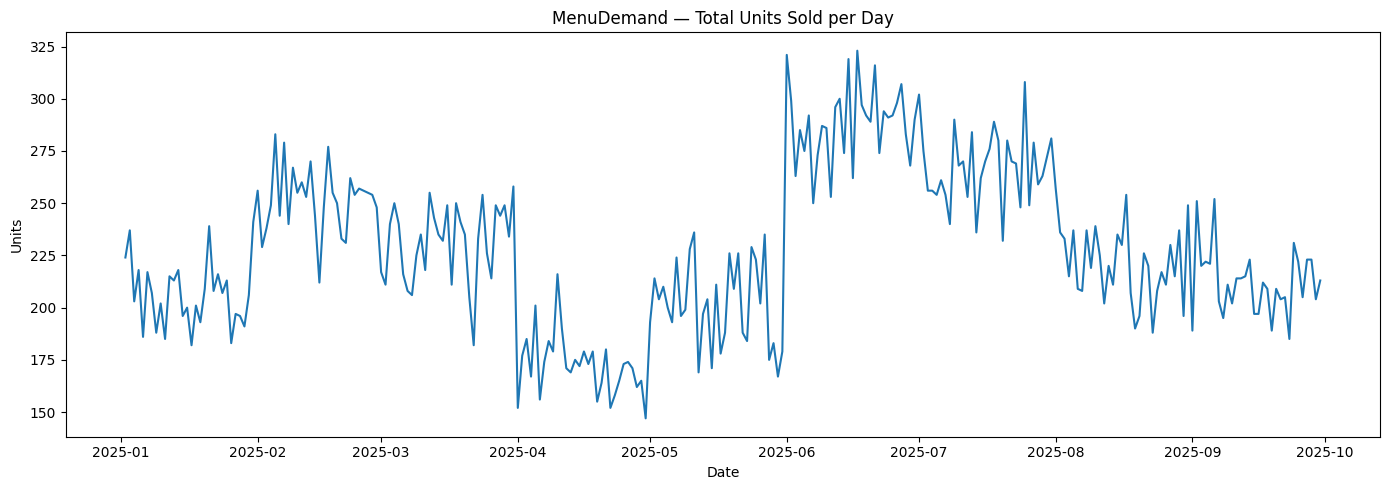

,month,sum,mean
0,2025-01,6191,206.366667
1,2025-02,7059,252.107143
2,2025-03,7165,231.129032
3,2025-04,5165,172.166667
4,2025-05,6241,201.322581
5,2025-06,8649,288.300000
6,2025-07,8286,267.290323
7,2025-08,6857,221.193548
8,2025-09,6360,212.000000


In [7]:
daily_units = items.groupby("Date").size().rename("units").reset_index()

plt.figure(figsize=(14,5))
plt.plot(daily_units["Date"], daily_units["units"])
plt.title("MenuDemand — Total Units Sold per Day")
plt.xlabel("Date")
plt.ylabel("Units")
plt.tight_layout()
plt.savefig(ASSET_DATA/"daily_total_units.png", dpi=180, bbox_inches="tight")
plt.show()

monthly = (
    daily_units.assign(month=daily_units["Date"].dt.to_period("M").astype(str))
    .groupby("month")["units"]
    .agg(["sum","mean"])
    .reset_index()
)
display(monthly)
monthly.to_csv(REPORTS/"monthly_demand_summary.csv", index=False)

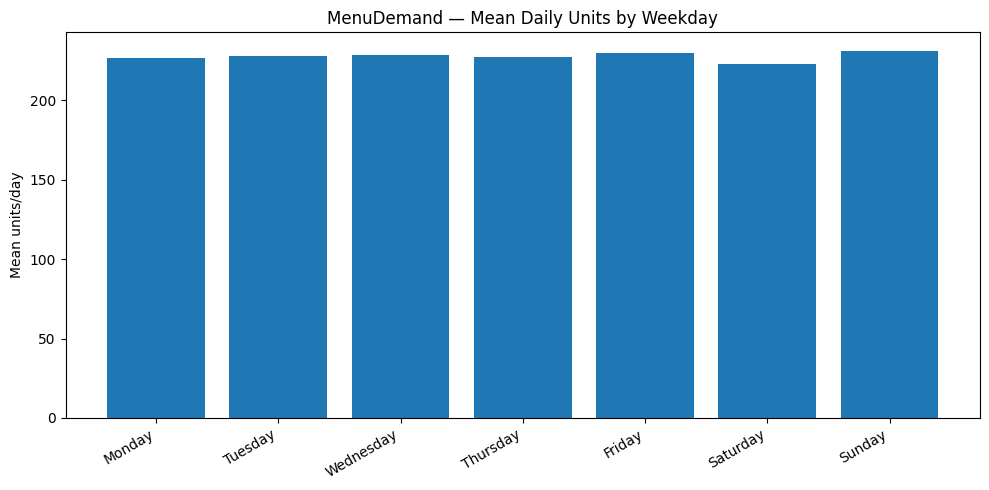

,weekday,mean,median,std
0,Monday,226.487179,217.0,37.829167
1,Tuesday,227.948718,226.0,40.489082
2,Wednesday,228.552632,225.0,39.665968
3,Thursday,227.307692,222.0,36.243441
4,Friday,230.076923,231.0,39.970637
5,Saturday,223.179487,219.0,35.340354
6,Sunday,231.358974,232.0,38.705016


In [8]:
weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
wd = daily_units.copy()
wd["weekday"] = wd["Date"].dt.day_name()

weekday_summary = (
    wd.groupby("weekday")["units"]
    .agg(["mean","median","std"])
    .reindex(weekday_order)
    .reset_index()
)

plt.figure(figsize=(10,5))
plt.bar(weekday_summary["weekday"], weekday_summary["mean"])
plt.title("MenuDemand — Mean Daily Units by Weekday")
plt.ylabel("Mean units/day")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(ASSET_DATA/"weekday_mean_units.png", dpi=180, bbox_inches="tight")
plt.show()
display(weekday_summary)

,ProductId,ProductDisplay,Category,units
47,50,Friendly Coffee (Ice),Coffee,715
46,49,Friendly Coffee (Hot),Coffee,708
3,6,Americano (Hot Arabica),Coffee,706
8,11,BLACK (Houseblend),Menu Gedhe,704
62,65,Lemons,Other,702
22,25,Butterscotch,Coffee,701
34,37,Chocolate (Gedhe),Menu Gedhe,700
76,79,Shakencano,Coffee,699
72,75,Not Tiramisu Latte (Gedhe),Menu Gedhe,698
84,87,Upgrade Beans (Arabica),Add on,698


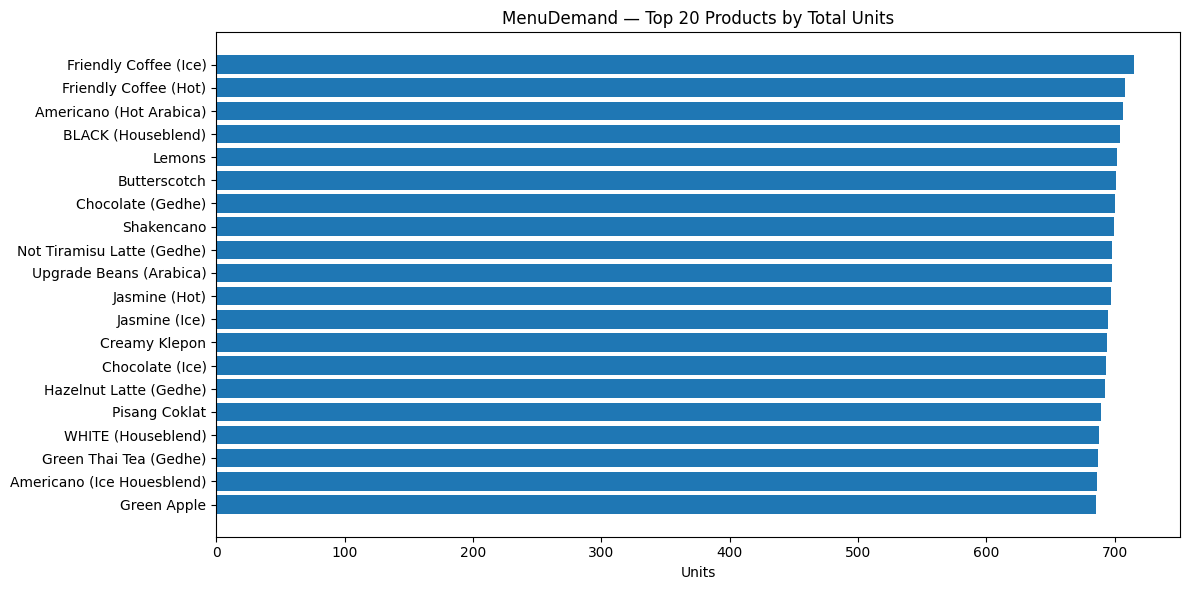

In [9]:
top_products = (
    items.groupby(["ProductId","ProductDisplay","Category"])
    .size()
    .rename("units")
    .reset_index()
    .sort_values("units", ascending=False)
)
top_products.to_csv(REPORTS/"product_total_units.csv", index=False)
display(top_products.head(20))

plt.figure(figsize=(12,6))
p = top_products.head(20).sort_values("units")
plt.barh(p["ProductDisplay"], p["units"])
plt.title("MenuDemand — Top 20 Products by Total Units")
plt.xlabel("Units")
plt.tight_layout()
plt.savefig(ASSET_DATA/"top20_products_total_units.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Product × Day panel

In [10]:
active_products = (
    items[["ProductId","ProductDisplay","ProductName","Variant","Category","Price"]]
    .drop_duplicates("ProductId")
    .sort_values("ProductId")
    .reset_index(drop=True)
)

dates = pd.date_range(tx["Date"].min(), tx["Date"].max(), freq="D")
idx = pd.MultiIndex.from_product(
    [active_products["ProductId"].tolist(), dates],
    names=["ProductId","Date"]
)
panel = pd.DataFrame(index=idx).reset_index()

daily_product = (
    items.groupby(["ProductId","Date"])
    .size()
    .rename("demand")
    .reset_index()
)

panel = panel.merge(daily_product, on=["ProductId","Date"], how="left")
panel["demand"] = panel["demand"].fillna(0).astype(float)
panel = panel.merge(active_products, on="ProductId", how="left", validate="many_to_one")

panel_audit = {
    "active_products": int(len(active_products)),
    "days": int(len(dates)),
    "panel_rows": int(len(panel)),
    "zero_demand_rate": float(panel["demand"].eq(0).mean()),
    "mean_demand": float(panel["demand"].mean()),
    "median_demand": float(panel["demand"].median()),
    "p90": float(panel["demand"].quantile(.90)),
    "p95": float(panel["demand"].quantile(.95)),
    "p99": float(panel["demand"].quantile(.99)),
    "max": float(panel["demand"].max()),
}
print(json.dumps(panel_audit, indent=2))
(REPORTS/"product_day_panel_audit.json").write_text(json.dumps(panel_audit, indent=2), encoding="utf-8")

{
  "active_products": 94,
  "days": 272,
  "panel_rows": 25568,
  "zero_demand_rate": 0.09625312891113892,
  "mean_demand": 2.4238501251564455,
  "median_demand": 2.0,
  "p90": 5.0,
  "p95": 5.0,
  "p99": 7.0,
  "max": 10.0
}


226

## 6. Granularity decision

In [11]:
outlet_daily = items.groupby(["Outlet","ProductId","Date"]).size().rename("demand").reset_index()
outlets = sorted(items["Outlet"].unique())

op_idx = pd.MultiIndex.from_product(
    [outlets, active_products["ProductId"].tolist(), dates],
    names=["Outlet","ProductId","Date"]
)
op_panel = pd.DataFrame(index=op_idx).reset_index()
op_panel = op_panel.merge(outlet_daily, on=["Outlet","ProductId","Date"], how="left")
op_panel["demand"] = op_panel["demand"].fillna(0)

granularity = {
    "product_day_zero_rate": float(panel["demand"].eq(0).mean()),
    "outlet_product_day_zero_rate": float(op_panel["demand"].eq(0).mean()),
    "product_day_mean": float(panel["demand"].mean()),
    "outlet_product_day_mean": float(op_panel["demand"].mean()),
}
print(json.dumps(granularity, indent=2))
(REPORTS/"granularity_comparison.json").write_text(json.dumps(granularity, indent=2), encoding="utf-8")

{
  "product_day_zero_rate": 0.09625312891113892,
  "outlet_product_day_zero_rate": 0.4682285148101794,
  "product_day_mean": 2.4238501251564455,
  "outlet_product_day_mean": 0.8079500417188152
}


195

The MVP uses Product × Day because Outlet × Product × Day is substantially sparser.

## 7. Leakage-safe features

In [12]:
def add_features(df):
    df = df.sort_values(["ProductId","Date"]).copy()
    grp = df.groupby("ProductId", group_keys=False)

    for lag in [1,2,3,7,14,28]:
        df[f"lag_{lag}"] = grp["demand"].shift(lag)

    shifted = grp["demand"].shift(1)

    for w in [3,7,14,28]:
        df[f"rolling_mean_{w}"] = (
            shifted.groupby(df["ProductId"])
            .rolling(w, min_periods=1)
            .mean()
            .reset_index(level=0, drop=True)
        )

    for w in [7,28]:
        df[f"rolling_std_{w}"] = (
            shifted.groupby(df["ProductId"])
            .rolling(w, min_periods=2)
            .std()
            .reset_index(level=0, drop=True)
        )

    df["expanding_mean"] = (
        shifted.groupby(df["ProductId"])
        .expanding(min_periods=1)
        .mean()
        .reset_index(level=0, drop=True)
    )

    df["day_of_week"] = df["Date"].dt.dayofweek
    df["day_of_month"] = df["Date"].dt.day
    df["week_of_year"] = df["Date"].dt.isocalendar().week.astype(int)
    df["month"] = df["Date"].dt.month
    df["is_weekend"] = df["day_of_week"].isin([5,6]).astype(int)

    df["dow_sin"] = np.sin(2*np.pi*df["day_of_week"]/7)
    df["dow_cos"] = np.cos(2*np.pi*df["day_of_week"]/7)
    df["month_sin"] = np.sin(2*np.pi*df["month"]/12)
    df["month_cos"] = np.cos(2*np.pi*df["month"]/12)

    return df

feat = add_features(panel)
model_df = feat.dropna(subset=["lag_28"]).copy()

print(model_df.shape)
print(model_df["Date"].min().date(), "→", model_df["Date"].max().date())
display(model_df.head())

(22936, 30)
2025-01-30 → 2025-09-30


,ProductId,Date,demand,ProductDisplay,ProductName,Variant,Category,Price,lag_1,lag_2,...,expanding_mean,day_of_week,day_of_month,week_of_year,month,is_weekend,dow_sin,dow_cos,month_sin,month_cos
28,3,2025-01-30,6.0,Air Mineral,Air Mineral,-,Other,5000,1.0,4.0,...,2.464286,3,30,5,1,0,0.433884,-0.900969,0.500000,0.866025
29,3,2025-01-31,2.0,Air Mineral,Air Mineral,-,Other,5000,6.0,1.0,...,2.586207,4,31,5,1,0,-0.433884,-0.900969,0.500000,0.866025
30,3,2025-02-01,5.0,Air Mineral,Air Mineral,-,Other,5000,2.0,6.0,...,2.566667,5,1,5,2,1,-0.974928,-0.222521,0.866025,0.500000
31,3,2025-02-02,2.0,Air Mineral,Air Mineral,-,Other,5000,5.0,2.0,...,2.645161,6,2,5,2,1,-0.781831,0.623490,0.866025,0.500000
32,3,2025-02-03,1.0,Air Mineral,Air Mineral,-,Other,5000,2.0,5.0,...,2.625000,0,3,6,2,0,0.000000,1.000000,0.866025,0.500000


## 8. Strict temporal split

In [13]:
TRAIN_END = pd.Timestamp("2025-07-31")
VAL_START = pd.Timestamp("2025-08-01")
VAL_END = pd.Timestamp("2025-08-31")
TEST_START = pd.Timestamp("2025-09-01")
TEST_END = pd.Timestamp("2025-09-30")

train_df = model_df[model_df["Date"] <= TRAIN_END].copy()
val_df = model_df[(model_df["Date"] >= VAL_START) & (model_df["Date"] <= VAL_END)].copy()
test_df = model_df[(model_df["Date"] >= TEST_START) & (model_df["Date"] <= TEST_END)].copy()

assert len(train_df) and len(val_df) and len(test_df)
assert train_df["Date"].max() < val_df["Date"].min()
assert val_df["Date"].max() < test_df["Date"].min()

split_summary = pd.DataFrame([
    ["train", len(train_df), train_df["Date"].min(), train_df["Date"].max()],
    ["validation", len(val_df), val_df["Date"].min(), val_df["Date"].max()],
    ["test", len(test_df), test_df["Date"].min(), test_df["Date"].max()],
], columns=["split","rows","start","end"])

display(split_summary)
split_summary.to_csv(REPORTS/"temporal_split_summary.csv", index=False)

,split,rows,start,end
0,train,17202,2025-01-30,2025-07-31
1,validation,2914,2025-08-01,2025-08-31
2,test,2820,2025-09-01,2025-09-30


## 9. Metrics

In [14]:
def metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = np.abs(y_true).sum()

    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(mean_squared_error(y_true, y_pred) ** 0.5),
        "WAPE": float(np.abs(y_true-y_pred).sum()/denom) if denom > 0 else np.nan,
        "Bias": float(np.mean(y_pred-y_true)),
        "MeanActual": float(np.mean(y_true)),
        "MeanPred": float(np.mean(y_pred)),
        "N": int(len(y_true)),
    }

def clip_nonnegative(x):
    return np.clip(np.asarray(x, dtype=float), 0, None)

## 10. Temporal baselines

In [15]:
baseline_specs = {
    "Naive-1": "lag_1",
    "Seasonal-7": "lag_7",
    "Rolling-7": "rolling_mean_7",
    "Rolling-28": "rolling_mean_28",
}

baseline_rows = []
for name, col in baseline_specs.items():
    pred = clip_nonnegative(val_df[col].values)
    baseline_rows.append({
        "model": name,
        "model_type": "baseline",
        **metrics(val_df["demand"].values, pred)
    })

baseline_val = pd.DataFrame(baseline_rows).sort_values(["MAE","RMSE"]).reset_index(drop=True)
display(baseline_val)
baseline_val.to_csv(REPORTS/"validation_baselines.csv", index=False)

,model,model_type,MAE,RMSE,WAPE,Bias,MeanActual,MeanPred,N
0,Rolling-28,baseline,1.289477,1.582675,0.547985,0.249841,2.353123,2.602964,2914
1,Rolling-7,baseline,1.311697,1.632700,0.557428,0.063732,2.353123,2.416855,2914
2,Naive-1,baseline,1.684969,2.144249,0.716057,0.010981,2.353123,2.364104,2914
3,Seasonal-7,baseline,1.715168,2.199551,0.728890,0.122169,2.353123,2.475292,2914


## 11. Learned model candidates

In [16]:
FEATURE_COLS = [
    "ProductId","Category","Price",
    "lag_1","lag_2","lag_3","lag_7","lag_14","lag_28",
    "rolling_mean_3","rolling_mean_7","rolling_mean_14","rolling_mean_28",
    "rolling_std_7","rolling_std_28","expanding_mean",
    "day_of_week","day_of_month","week_of_year","month","is_weekend",
    "dow_sin","dow_cos","month_sin","month_cos",
]
CATEGORICAL_COLS = ["ProductId","Category"]

def prepare_X(df):
    X = df[FEATURE_COLS].copy()
    for c in CATEGORICAL_COLS:
        X[c] = X[c].astype("category")
    return X

X_train = prepare_X(train_df)
y_train = train_df["demand"].astype(float)
X_val = prepare_X(val_df)
y_val = val_df["demand"].astype(float)

candidate_params = {
    "LGBM-Poisson": dict(
        objective="poisson", n_estimators=700, learning_rate=0.035,
        num_leaves=31, min_child_samples=30, subsample=0.90,
        colsample_bytree=0.90, reg_alpha=0.05, reg_lambda=0.20,
        random_state=SEED, n_jobs=-1, verbosity=-1
    ),
    "LGBM-L1": dict(
        objective="regression_l1", n_estimators=700, learning_rate=0.035,
        num_leaves=31, min_child_samples=30, subsample=0.90,
        colsample_bytree=0.90, reg_alpha=0.05, reg_lambda=0.20,
        random_state=SEED, n_jobs=-1, verbosity=-1
    ),
    "LGBM-Tweedie": dict(
        objective="tweedie", tweedie_variance_power=1.25,
        n_estimators=700, learning_rate=0.035,
        num_leaves=31, min_child_samples=30, subsample=0.90,
        colsample_bytree=0.90, reg_alpha=0.05, reg_lambda=0.20,
        random_state=SEED, n_jobs=-1, verbosity=-1
    ),
}

learned_models = {}
learned_rows = []

for name, params in candidate_params.items():
    print("[TRAIN]", name, flush=True)
    m = LGBMRegressor(**params)
    m.fit(X_train, y_train, categorical_feature=CATEGORICAL_COLS)
    pred = clip_nonnegative(m.predict(X_val))
    met = metrics(y_val, pred)
    learned_models[name] = m
    learned_rows.append({
        "model": name,
        "model_type": "learned",
        **met
    })
    print(name, met)

learned_val = pd.DataFrame(learned_rows).sort_values(["MAE","RMSE"]).reset_index(drop=True)
display(learned_val)
learned_val.to_csv(REPORTS/"validation_learned_models.csv", index=False)

[TRAIN] LGBM-Poisson
LGBM-Poisson {'MAE': 1.4015952336480897, 'RMSE': 1.6993051563015922, 'WAPE': 0.5956319834986924, 'Bias': 0.6233528514305622, 'MeanActual': 2.3531228551818804, 'MeanPred': 2.976475706612443, 'N': 2914}
[TRAIN] LGBM-L1
LGBM-L1 {'MAE': 1.32675888210725, 'RMSE': 1.6206689007439068, 'WAPE': 0.5638289897127792, 'Bias': 0.46368811684602823, 'MeanActual': 2.3531228551818804, 'MeanPred': 2.816810972027908, 'N': 2914}
[TRAIN] LGBM-Tweedie
LGBM-Tweedie {'MAE': 1.4257975726183416, 'RMSE': 1.7343332755854943, 'WAPE': 0.605917183405257, 'Bias': 0.5908550415189774, 'MeanActual': 2.3531228551818804, 'MeanPred': 2.943977896700858, 'N': 2914}


,model,model_type,MAE,RMSE,WAPE,Bias,MeanActual,MeanPred,N
0,LGBM-L1,learned,1.326759,1.620669,0.563829,0.463688,2.353123,2.816811,2914
1,LGBM-Poisson,learned,1.401595,1.699305,0.595632,0.623353,2.353123,2.976476,2914
2,LGBM-Tweedie,learned,1.425798,1.734333,0.605917,0.590855,2.353123,2.943978,2914


## 12. Correct operational champion selection

,model,model_type,MAE,RMSE,WAPE,Bias,MeanActual,MeanPred,N
0,Rolling-28,baseline,1.289477,1.582675,0.547985,0.249841,2.353123,2.602964,2914
1,Rolling-7,baseline,1.311697,1.632700,0.557428,0.063732,2.353123,2.416855,2914
2,LGBM-L1,learned,1.326759,1.620669,0.563829,0.463688,2.353123,2.816811,2914
3,LGBM-Poisson,learned,1.401595,1.699305,0.595632,0.623353,2.353123,2.976476,2914
4,LGBM-Tweedie,learned,1.425798,1.734333,0.605917,0.590855,2.353123,2.943978,2914
5,Naive-1,baseline,1.684969,2.144249,0.716057,0.010981,2.353123,2.364104,2914
6,Seasonal-7,baseline,1.715168,2.199551,0.728890,0.122169,2.353123,2.475292,2914


{
  "selection_metric": "validation_MAE",
  "operational_champion": {
    "name": "Rolling-28",
    "type": "baseline",
    "validation_metrics": {
      "MAE": 1.2894769095009315,
      "RMSE": 1.58267549852879,
      "WAPE": 0.5479853746953062,
      "Bias": 0.24984067065398566,
      "MeanActual": 2.3531228551818804,
      "MeanPred": 2.602963525835866,
      "N": 2914
    }
  },
  "best_learned_model": {
    "name": "LGBM-L1",
    "validation_metrics": {
      "MAE": 1.32675888210725,
      "RMSE": 1.6206689007439068,
      "WAPE": 0.5638289897127792,
      "Bias": 0.46368811684602823,
      "MeanActual": 2.3531228551818804,
      "MeanPred": 2.816810972027908,
      "N": 2914
    }
  },
  "selection_note": "Held-out test is not used for champion selection."
}


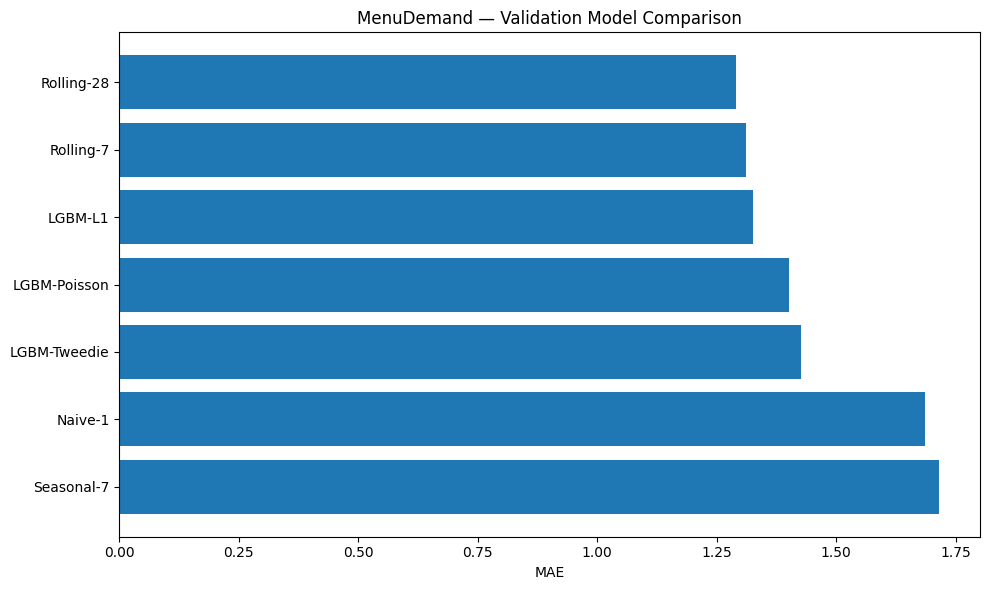

[SELECTION] Operational champion: Rolling-28 baseline
[SELECTION] Best learned model: LGBM-L1


In [17]:
comparison = pd.concat([baseline_val, learned_val], ignore_index=True)
comparison = comparison.sort_values(["MAE","RMSE"]).reset_index(drop=True)

display(comparison)
comparison.to_csv(REPORTS/"validation_model_comparison.csv", index=False)

operational_row = comparison.iloc[0]
operational_champion_name = str(operational_row["model"])
operational_champion_type = str(operational_row["model_type"])

best_learned_row = learned_val.iloc[0]
best_learned_name = str(best_learned_row["model"])

def row_metrics(row):
    return {
        "MAE": float(row["MAE"]),
        "RMSE": float(row["RMSE"]),
        "WAPE": float(row["WAPE"]),
        "Bias": float(row["Bias"]),
        "MeanActual": float(row["MeanActual"]),
        "MeanPred": float(row["MeanPred"]),
        "N": int(row["N"]),
    }

selection = {
    "selection_metric": "validation_MAE",
    "operational_champion": {
        "name": operational_champion_name,
        "type": operational_champion_type,
        "validation_metrics": row_metrics(operational_row),
    },
    "best_learned_model": {
        "name": best_learned_name,
        "validation_metrics": row_metrics(best_learned_row),
    },
    "selection_note": "Held-out test is not used for champion selection."
}

print(json.dumps(selection, indent=2))
(REPORTS/"model_selection.json").write_text(json.dumps(selection, indent=2), encoding="utf-8")

plt.figure(figsize=(10,6))
p = comparison.sort_values("MAE", ascending=False)
plt.barh(p["model"], p["MAE"])
plt.title("MenuDemand — Validation Model Comparison")
plt.xlabel("MAE")
plt.tight_layout()
plt.savefig(ASSET_TRAIN/"validation_model_comparison_mae.png", dpi=180, bbox_inches="tight")
plt.show()

print("[SELECTION] Operational champion:", operational_champion_name, operational_champion_type)
print("[SELECTION] Best learned model:", best_learned_name)

## 13. Refit best learned model on Train + Validation

In [18]:
trainval_df = pd.concat([train_df, val_df], ignore_index=True).sort_values(["ProductId","Date"])
X_trainval = prepare_X(trainval_df)
y_trainval = trainval_df["demand"].astype(float)

best_learned_model = LGBMRegressor(**candidate_params[best_learned_name])
best_learned_model.fit(
    X_trainval,
    y_trainval,
    categorical_feature=CATEGORICAL_COLS
)

BEST_LEARNED_PATH = MODELS/"menudemand_best_learned_lgbm.joblib"
joblib.dump(best_learned_model, BEST_LEARNED_PATH)

print("[MODEL] saved:", BEST_LEARNED_PATH)

[MODEL] saved: /kaggle/working/menudemand_13pct_v2/models/menudemand_best_learned_lgbm.joblib


## 14. Official held-out test

In [19]:
X_test = prepare_X(test_df)
y_test = test_df["demand"].astype(float)

learned_test_pred = clip_nonnegative(best_learned_model.predict(X_test))
learned_test_metrics = metrics(y_test, learned_test_pred)

if operational_champion_type == "baseline":
    champion_col = baseline_specs[operational_champion_name]
    operational_test_pred = clip_nonnegative(test_df[champion_col].values)
else:
    if operational_champion_name == best_learned_name:
        operational_model = best_learned_model
    else:
        operational_model = LGBMRegressor(**candidate_params[operational_champion_name])
        operational_model.fit(
            X_trainval,
            y_trainval,
            categorical_feature=CATEGORICAL_COLS
        )
    operational_test_pred = clip_nonnegative(operational_model.predict(X_test))

operational_test_metrics = metrics(y_test, operational_test_pred)

official_test = {
    "test_start": str(test_df["Date"].min().date()),
    "test_end": str(test_df["Date"].max().date()),
    "forecast_protocol": "rolling one-day-ahead",
    "selection_rule": "validation MAE only",
    "operational_champion": {
        "name": operational_champion_name,
        "type": operational_champion_type,
        "metrics": operational_test_metrics,
    },
    "best_learned_model": {
        "name": best_learned_name,
        "metrics": learned_test_metrics,
    },
    "note": "Test results do not retroactively alter champion selection."
}

print(json.dumps(official_test, indent=2))
(REPORTS/"official_test_metrics.json").write_text(json.dumps(official_test, indent=2), encoding="utf-8")

{
  "test_start": "2025-09-01",
  "test_end": "2025-09-30",
  "forecast_protocol": "rolling one-day-ahead",
  "selection_rule": "validation MAE only",
  "operational_champion": {
    "name": "Rolling-28",
    "type": "baseline",
    "metrics": {
      "MAE": 1.2314842958459982,
      "RMSE": 1.540688734282308,
      "WAPE": 0.5460354896675652,
      "Bias": 0.04146403242147923,
      "MeanActual": 2.25531914893617,
      "MeanPred": 2.2967831813576494,
      "N": 2820
    }
  },
  "best_learned_model": {
    "name": "LGBM-L1",
    "metrics": {
      "MAE": 1.2234185546672556,
      "RMSE": 1.5437866936075686,
      "WAPE": 0.5424591704656699,
      "Bias": -0.027325136832312323,
      "MeanActual": 2.25531914893617,
      "MeanPred": 2.227994012103858,
      "N": 2820
    }
  },
  "note": "Test results do not retroactively alter champion selection."
}


863

## 15. Test prediction table

In [20]:
test_results = test_df[
    ["Date","ProductId","ProductDisplay","Category","Price","demand"]
].copy()

test_results["operational_prediction"] = operational_test_pred
test_results["learned_prediction"] = learned_test_pred
test_results["operational_error"] = test_results["operational_prediction"] - test_results["demand"]
test_results["learned_error"] = test_results["learned_prediction"] - test_results["demand"]
test_results["operational_abs_error"] = test_results["operational_error"].abs()
test_results["learned_abs_error"] = test_results["learned_error"].abs()

test_results.to_csv(REPORTS/"test_predictions.csv", index=False)
display(test_results.head())

,Date,ProductId,ProductDisplay,Category,Price,demand,operational_prediction,learned_prediction,operational_error,learned_error,operational_abs_error,learned_abs_error
242,2025-09-01,3,Air Mineral,Other,5000,1.0,2.321429,2.054951,1.321429,1.054951,1.321429,1.054951
243,2025-09-02,3,Air Mineral,Other,5000,3.0,2.214286,2.130966,-0.785714,-0.869034,0.785714,0.869034
244,2025-09-03,3,Air Mineral,Other,5000,3.0,2.178571,2.129360,-0.821429,-0.870640,0.821429,0.870640
245,2025-09-04,3,Air Mineral,Other,5000,2.0,2.107143,2.090793,0.107143,0.090793,0.107143,0.090793
246,2025-09-05,3,Air Mineral,Other,5000,2.0,2.035714,2.108626,0.035714,0.108626,0.035714,0.108626


## 16. Held-out comparison visuals

,model,role,MAE,RMSE,WAPE,Bias,MeanActual,MeanPred,N
0,Rolling-28,operational_champion,1.231484,1.540689,0.546035,0.041464,2.255319,2.296783,2820
1,LGBM-L1,best_learned_model,1.223419,1.543787,0.542459,-0.027325,2.255319,2.227994,2820


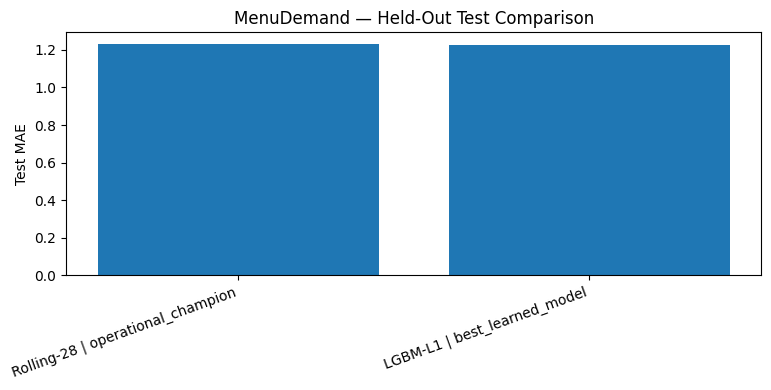

In [21]:
test_comparison = pd.DataFrame([
    {"model": operational_champion_name, "role": "operational_champion", **operational_test_metrics},
    {"model": best_learned_name, "role": "best_learned_model", **learned_test_metrics},
])
display(test_comparison)
test_comparison.to_csv(REPORTS/"official_test_model_comparison.csv", index=False)

plt.figure(figsize=(8,4))
plt.bar(test_comparison["model"] + " | " + test_comparison["role"], test_comparison["MAE"])
plt.ylabel("Test MAE")
plt.title("MenuDemand — Held-Out Test Comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(ASSET_EVAL/"test_operational_vs_learned_mae.png", dpi=180, bbox_inches="tight")
plt.show()

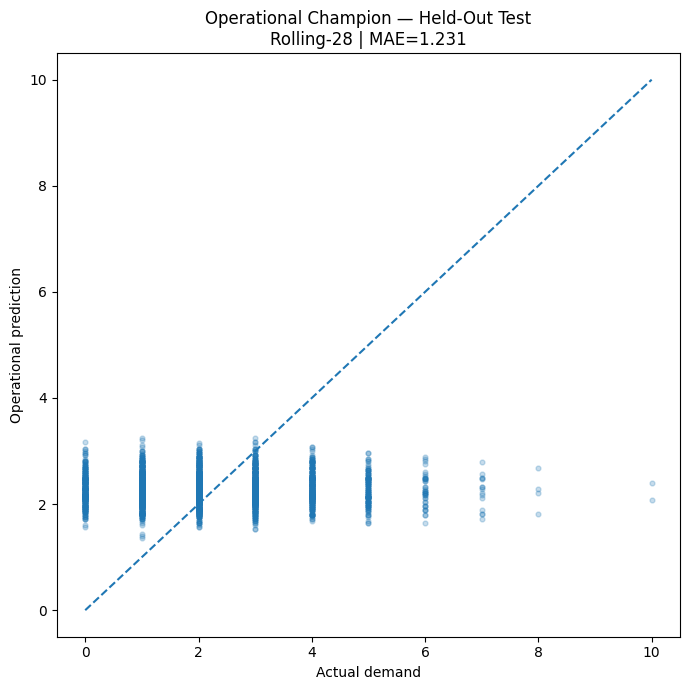

In [22]:
sample = test_results.sample(min(2500, len(test_results)), random_state=SEED)

plt.figure(figsize=(7,7))
plt.scatter(sample["demand"], sample["operational_prediction"], s=12, alpha=.25)
mx = max(sample["demand"].max(), sample["operational_prediction"].max())
plt.plot([0,mx],[0,mx],"--")
plt.xlabel("Actual demand")
plt.ylabel("Operational prediction")
plt.title(
    f"Operational Champion — Held-Out Test\n"
    f"{operational_champion_name} | MAE={operational_test_metrics['MAE']:.3f}"
)
plt.tight_layout()
plt.savefig(ASSET_EVAL/"test_actual_vs_operational_prediction.png", dpi=180, bbox_inches="tight")
plt.show()

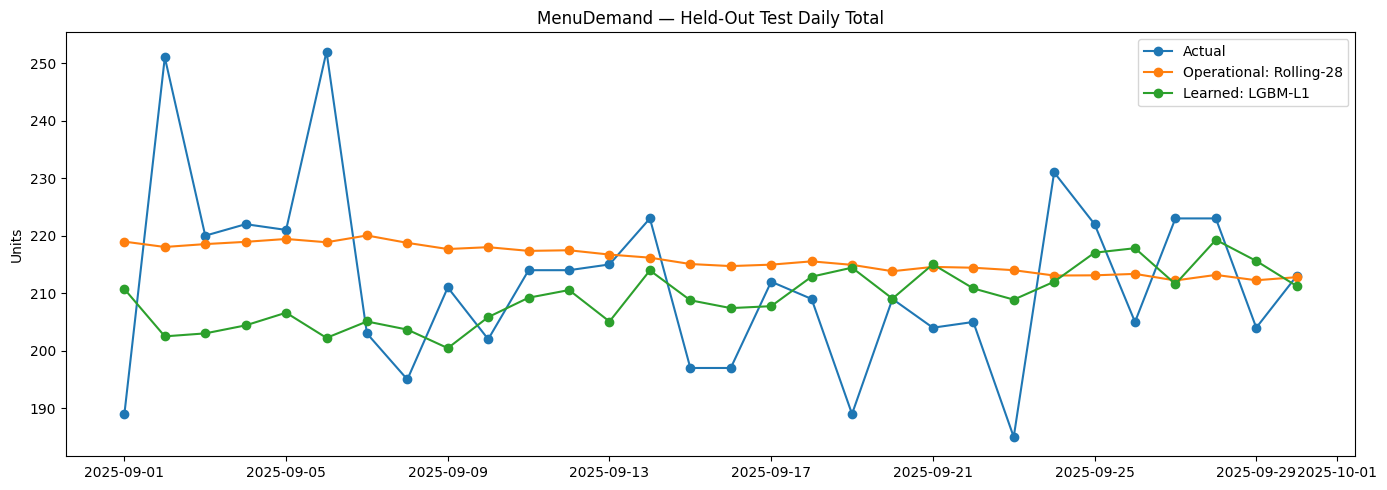

In [23]:
daily_test = (
    test_results.groupby("Date")[
        ["demand","operational_prediction","learned_prediction"]
    ].sum().reset_index()
)

plt.figure(figsize=(14,5))
plt.plot(daily_test["Date"], daily_test["demand"], marker="o", label="Actual")
plt.plot(daily_test["Date"], daily_test["operational_prediction"], marker="o", label=f"Operational: {operational_champion_name}")
plt.plot(daily_test["Date"], daily_test["learned_prediction"], marker="o", label=f"Learned: {best_learned_name}")
plt.title("MenuDemand — Held-Out Test Daily Total")
plt.ylabel("Units")
plt.legend()
plt.tight_layout()
plt.savefig(ASSET_EVAL/"test_daily_total_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 17. Per-product and per-category operational metrics

,ProductId,ProductDisplay,Category,MAE,RMSE,WAPE,Bias,MeanActual,MeanPred,N
6,9,Apple Pie Latte (Gedhe),Menu Gedhe,1.816667,2.219100,0.778571,0.047619,2.333333,2.380952,30.0
74,77,Red Apple,Tea,1.684524,2.074310,0.647894,-0.208333,2.600000,2.391667,30.0
1,4,Americano (Hot Houseblend),Coffee,1.561905,1.864135,0.743764,0.411905,2.100000,2.511905,30.0
3,6,Americano (Hot Arabica),Coffee,1.536905,1.990250,0.523945,-0.484524,2.933333,2.448810,30.0
79,82,Summer,Tea,1.511905,1.814811,0.638833,0.371429,2.366667,2.738095,30.0
51,54,Green Thai Tea (Gedhe),Menu Gedhe,1.485714,1.657261,0.718894,0.692857,2.066667,2.759524,30.0
35,38,Creamy Klepon,Other,1.484524,1.774716,0.685165,0.132143,2.166667,2.298810,30.0
22,25,Butterscotch,Coffee,1.476190,1.686481,0.632653,0.302381,2.333333,2.635714,30.0
36,39,Donat Polos,Snacks,1.476190,1.822502,0.805195,0.164286,1.833333,1.997619,30.0
34,37,Chocolate (Gedhe),Menu Gedhe,1.446429,1.897176,0.549277,-0.270238,2.633333,2.363095,30.0


,Category,MAE,RMSE,WAPE,Bias,MeanActual,MeanPred,N
3,Other,1.278492,1.592216,0.570755,0.013413,2.240000,2.253413,450.0
2,Menu Gedhe,1.236278,1.545807,0.539570,0.066855,2.291228,2.358083,570.0
1,Coffee,1.233543,1.560123,0.535866,0.001611,2.301961,2.303571,1020.0
5,Tea,1.217125,1.509891,0.540636,0.110165,2.251282,2.361447,390.0
0,Add on,1.180655,1.485148,0.507808,-0.147321,2.325000,2.177679,120.0
4,Snacks,1.178571,1.433200,0.588196,0.169841,2.003704,2.173545,270.0


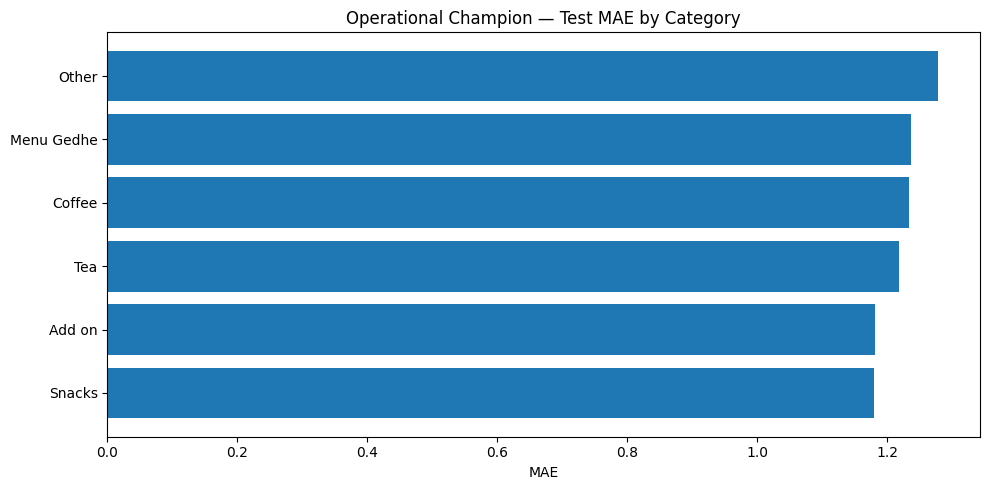

In [24]:
def grouped_metrics(g):
    return pd.Series(metrics(g["demand"].values, g["operational_prediction"].values))

per_product = (
    test_results.groupby(["ProductId","ProductDisplay","Category"], group_keys=False)
    .apply(grouped_metrics)
    .reset_index()
    .sort_values("MAE", ascending=False)
)

per_category = (
    test_results.groupby("Category", group_keys=False)
    .apply(grouped_metrics)
    .reset_index()
    .sort_values("MAE", ascending=False)
)

per_product.to_csv(REPORTS/"operational_test_metrics_per_product.csv", index=False)
per_category.to_csv(REPORTS/"operational_test_metrics_per_category.csv", index=False)

display(per_product.head(20))
display(per_category)

plt.figure(figsize=(10,5))
p = per_category.sort_values("MAE")
plt.barh(p["Category"], p["MAE"])
plt.title("Operational Champion — Test MAE by Category")
plt.xlabel("MAE")
plt.tight_layout()
plt.savefig(ASSET_EVAL/"operational_test_mae_by_category.png", dpi=180, bbox_inches="tight")
plt.show()

## 18. Failure analysis

In [25]:
worst = test_results.sort_values("operational_abs_error", ascending=False).head(30)
worst.to_csv(REPORTS/"operational_worst_test_errors.csv", index=False)
display(worst)

,Date,ProductId,ProductDisplay,Category,Price,demand,operational_prediction,learned_prediction,operational_error,learned_error,operational_abs_error,learned_abs_error
6782,2025-09-13,27,Candy Latte,Coffee,23000,10.0,2.071429,2.481224,-7.928571,-7.518776,7.928571,7.518776
11148,2025-09-27,43,Espresso Houseblend (Basic Espresso),Coffee,12000,10.0,2.392857,1.945622,-7.607143,-8.054378,7.607143,8.054378
1353,2025-09-24,7,Americano (Ice Arabica),Coffee,20000,8.0,1.821429,2.156459,-6.178571,-5.843541,6.178571,5.843541
8698,2025-09-25,34,Chocolate (Hot),Other,25000,8.0,2.035714,2.232693,-5.964286,-5.767307,5.964286,5.767307
20383,2025-09-14,77,Red Apple,Tea,21000,8.0,2.214286,1.807800,-5.785714,-6.192200,5.785714,6.192200
9507,2025-09-18,37,Chocolate (Gedhe),Menu Gedhe,30000,8.0,2.285714,2.179525,-5.714286,-5.820475,5.714286,5.820475
12779,2025-09-26,49,Friendly Coffee (Hot),Coffee,23000,8.0,2.678571,2.109888,-5.321429,-5.890112,5.321429,5.890112
10060,2025-09-27,39,Donat Polos,Snacks,10000,7.0,1.714286,2.673752,-5.285714,-4.326248,5.285714,4.326248
1897,2025-09-24,9,Apple Pie Latte (Gedhe),Menu Gedhe,30000,7.0,1.821429,2.881900,-5.178571,-4.118100,5.178571,4.118100
25005,2025-09-12,94,Creamy Chocolate Cake,Other,30000,7.0,1.821429,1.902302,-5.178571,-5.097698,5.178571,5.097698


## 19. Best learned feature importance

,feature,importance
0,ProductId,4075
13,rolling_std_7,1676
15,expanding_mean,1625
14,rolling_std_28,1460
17,day_of_month,1343
12,rolling_mean_28,1283
11,rolling_mean_14,1240
18,week_of_year,943
10,rolling_mean_7,853
9,rolling_mean_3,767


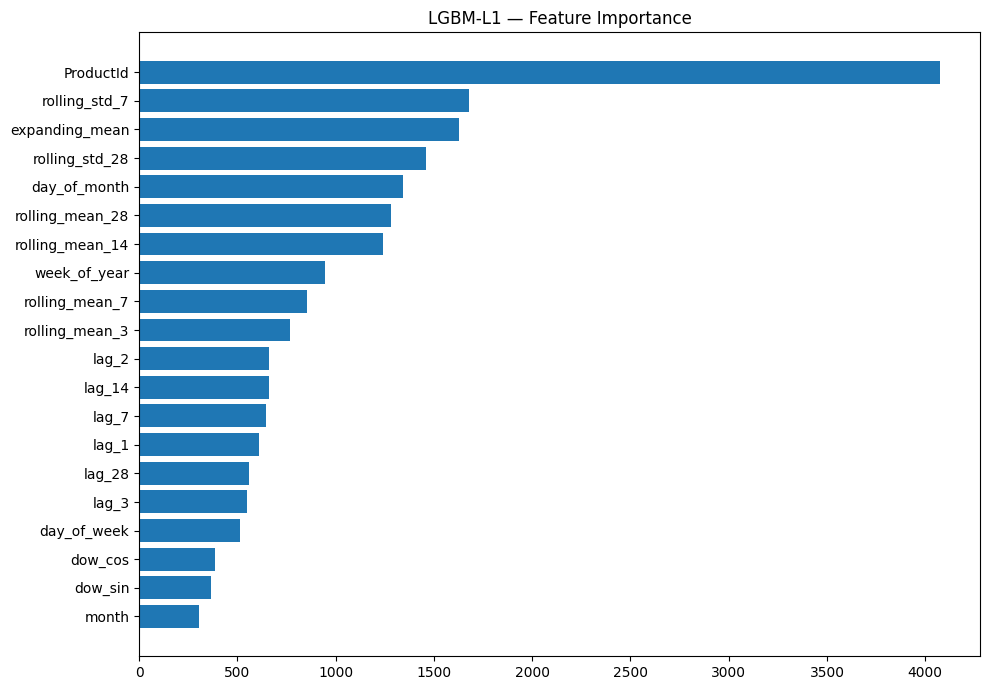

In [26]:
importance = pd.DataFrame({
    "feature": FEATURE_COLS,
    "importance": best_learned_model.feature_importances_,
}).sort_values("importance", ascending=False)

importance.to_csv(REPORTS/"best_learned_feature_importance.csv", index=False)
display(importance.head(20))

plt.figure(figsize=(10,7))
p = importance.head(20).sort_values("importance")
plt.barh(p["feature"], p["importance"])
plt.title(f"{best_learned_name} — Feature Importance")
plt.tight_layout()
plt.savefig(ASSET_TRAIN/"best_learned_feature_importance_top20.png", dpi=180, bbox_inches="tight")
plt.show()

## 20. Next-day forecast using the operational champion

,ProductDisplay,Category,forecast_units,forecast_units_rounded
0,Friendly Coffee (Ice),Coffee,3.214286,3
1,Americano (Hot Arabica),Coffee,3.107143,3
2,Friendly Coffee (Hot),Coffee,2.928571,3
3,Pisang Coklat,Snacks,2.892857,3
4,Chocolate (Gedhe),Menu Gedhe,2.785714,3
5,Vanilla Latte,Coffee,2.785714,3
6,Green Apple,Tea,2.785714,3
7,Green Thai Tea,Tea,2.607143,3
8,Jasmine (Hot),Tea,2.607143,3
9,Basic Latte (Hot Houseblend),Coffee,2.607143,3


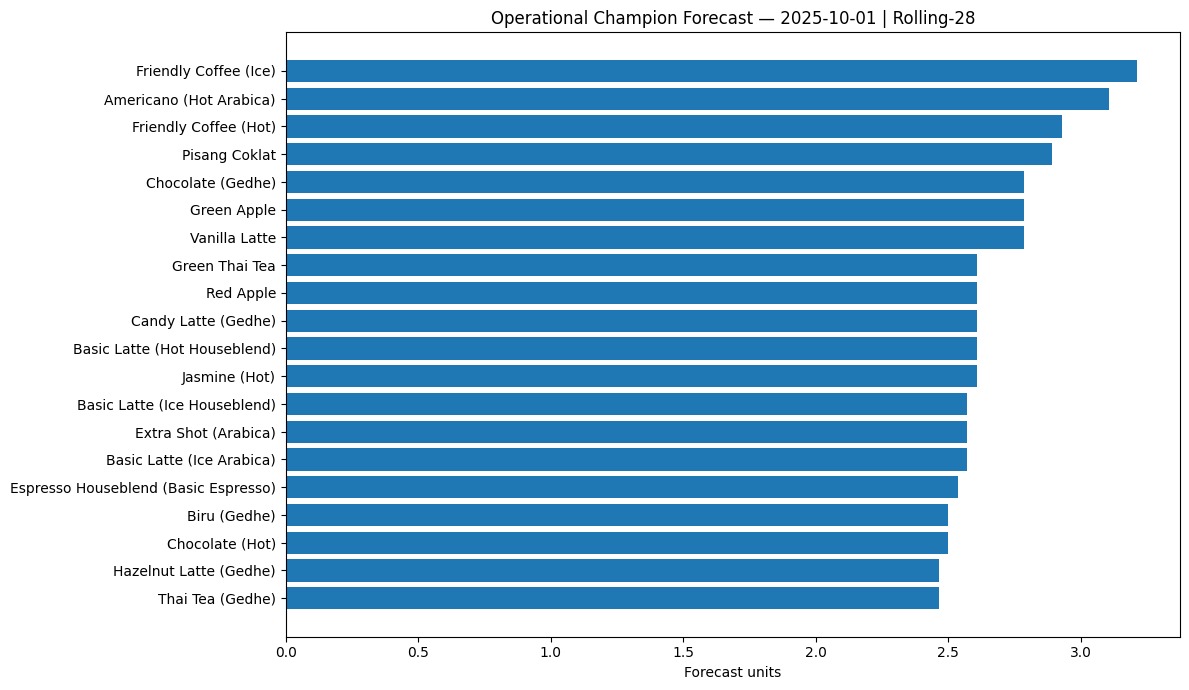

In [27]:
NEXT_DATE = tx["Date"].max() + pd.Timedelta(days=1)

if operational_champion_type == "baseline":
    if operational_champion_name == "Naive-1":
        future = (
            panel.sort_values(["ProductId","Date"])
            .groupby("ProductId")
            .tail(1)[["ProductId","demand"]]
            .rename(columns={"demand":"forecast_units"})
        )
    elif operational_champion_name == "Seasonal-7":
        target_hist_date = NEXT_DATE - pd.Timedelta(days=7)
        future = (
            panel[panel["Date"] == target_hist_date][["ProductId","demand"]]
            .rename(columns={"demand":"forecast_units"})
        )
    elif operational_champion_name == "Rolling-7":
        future = (
            panel.sort_values(["ProductId","Date"])
            .groupby("ProductId")
            .tail(7)
            .groupby("ProductId")["demand"]
            .mean()
            .rename("forecast_units")
            .reset_index()
        )
    elif operational_champion_name == "Rolling-28":
        future = (
            panel.sort_values(["ProductId","Date"])
            .groupby("ProductId")
            .tail(28)
            .groupby("ProductId")["demand"]
            .mean()
            .rename("forecast_units")
            .reset_index()
        )
    else:
        raise ValueError("Unknown baseline champion")

    future = active_products.merge(future, on="ProductId", how="left")

else:
    def build_next_day_features(panel_df, metadata, next_date):
        rows = []
        for product_id, g in panel_df.sort_values(["ProductId","Date"]).groupby("ProductId"):
            y = g["demand"].to_numpy(dtype=float)
            meta = metadata.loc[metadata["ProductId"] == product_id].iloc[0]

            def lag(n): return float(y[-n]) if len(y) >= n else np.nan
            def rmean(n): return float(np.mean(y[-n:]))
            def rstd(n):
                vals = y[-n:]
                return float(np.std(vals, ddof=1)) if len(vals) >= 2 else 0.0

            rows.append({
                "ProductId": int(product_id),
                "ProductDisplay": meta["ProductDisplay"],
                "ProductName": meta["ProductName"],
                "Variant": meta["Variant"],
                "Category": meta["Category"],
                "Price": float(meta["Price"]),
                "Date": next_date,
                "lag_1": lag(1), "lag_2": lag(2), "lag_3": lag(3),
                "lag_7": lag(7), "lag_14": lag(14), "lag_28": lag(28),
                "rolling_mean_3": rmean(3), "rolling_mean_7": rmean(7),
                "rolling_mean_14": rmean(14), "rolling_mean_28": rmean(28),
                "rolling_std_7": rstd(7), "rolling_std_28": rstd(28),
                "expanding_mean": float(np.mean(y)),
                "day_of_week": int(next_date.dayofweek),
                "day_of_month": int(next_date.day),
                "week_of_year": int(next_date.isocalendar().week),
                "month": int(next_date.month),
                "is_weekend": int(next_date.dayofweek in [5,6]),
                "dow_sin": float(np.sin(2*np.pi*next_date.dayofweek/7)),
                "dow_cos": float(np.cos(2*np.pi*next_date.dayofweek/7)),
                "month_sin": float(np.sin(2*np.pi*next_date.month/12)),
                "month_cos": float(np.cos(2*np.pi*next_date.month/12)),
            })
        return pd.DataFrame(rows)

    future = build_next_day_features(panel, active_products, NEXT_DATE)

    if operational_champion_name == best_learned_name:
        op_model = best_learned_model
    else:
        op_model = LGBMRegressor(**candidate_params[operational_champion_name])
        op_model.fit(X_trainval, y_trainval, categorical_feature=CATEGORICAL_COLS)

    future["forecast_units"] = clip_nonnegative(op_model.predict(prepare_X(future)))

future["forecast_date"] = NEXT_DATE
future["forecast_units_rounded"] = np.rint(future["forecast_units"]).astype(int)
future = future.sort_values("forecast_units", ascending=False).reset_index(drop=True)

future.to_csv(REPORTS/"next_day_forecast.csv", index=False)

display(future[["ProductDisplay","Category","forecast_units","forecast_units_rounded"]].head(25))

plt.figure(figsize=(12,7))
p = future.head(20).sort_values("forecast_units")
plt.barh(p["ProductDisplay"], p["forecast_units"])
plt.title(f"Operational Champion Forecast — {NEXT_DATE.date()} | {operational_champion_name}")
plt.xlabel("Forecast units")
plt.tight_layout()
plt.savefig(ASSET_PRED/"next_day_top20_forecast.png", dpi=180, bbox_inches="tight")
plt.show()

## 21. Config and final source of truth

In [28]:
forecast_config = {
    "project": "MenuDemand Forecast",
    "portfolio_progress": "13%",
    "task": "next-day product-level unit demand forecasting",
    "granularity": "Product x Day",
    "forecast_protocol": "rolling one-day-ahead",
    "selection_metric": "validation_MAE",
    "operational_champion": {
        "name": operational_champion_name,
        "type": operational_champion_type,
    },
    "best_learned_model": best_learned_name,
    "best_learned_model_file": BEST_LEARNED_PATH.name,
    "history_required_days": 28,
    "feature_columns": FEATURE_COLS,
    "categorical_columns": CATEGORICAL_COLS,
    "train_end": str(TRAIN_END.date()),
    "validation_period": [str(VAL_START.date()), str(VAL_END.date())],
    "test_period": [str(TEST_START.date()), str(TEST_END.date())],
}
(REPORTS/"forecast_config.json").write_text(json.dumps(forecast_config, indent=2), encoding="utf-8")
print(json.dumps(forecast_config, indent=2))

{
  "project": "MenuDemand Forecast",
  "portfolio_progress": "13%",
  "task": "next-day product-level unit demand forecasting",
  "granularity": "Product x Day",
  "forecast_protocol": "rolling one-day-ahead",
  "selection_metric": "validation_MAE",
  "operational_champion": {
    "name": "Rolling-28",
    "type": "baseline"
  },
  "best_learned_model": "LGBM-L1",
  "best_learned_model_file": "menudemand_best_learned_lgbm.joblib",
  "history_required_days": 28,
  "feature_columns": [
    "ProductId",
    "Category",
    "Price",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_3",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28",
    "rolling_std_7",
    "rolling_std_28",
    "expanding_mean",
    "day_of_week",
    "day_of_month",
    "week_of_year",
    "month",
    "is_weekend",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos"
  ],
  "categorical_columns": [
    "ProductId",
    "Category"
  ],
  "trai

In [29]:
final_summary = {
    "project": "MenuDemand Forecast",
    "portfolio_progress": "13%",
    "dataset": "Anonymous Transactional Dataset",
    "dataset_summary": {
        "receipts": int(len(tx)),
        "parsed_units": int(len(items)),
        "catalog_products": int(len(products)),
        "active_products": int(items["ProductId"].nunique()),
        "outlets": int(tx["Outlet"].nunique()),
        "days": int(tx["Date"].nunique()),
        "start_date": str(tx["Date"].min().date()),
        "end_date": str(tx["Date"].max().date()),
    },
    "raw_audit": raw_audit,
    "item_parsing_audit": parse_audit,
    "product_day_panel": panel_audit,
    "granularity_decision": granularity,
    "temporal_split": {
        "train_end": str(TRAIN_END.date()),
        "validation": [str(VAL_START.date()), str(VAL_END.date())],
        "test": [str(TEST_START.date()), str(TEST_END.date())],
    },
    "selection": selection,
    "official_test": official_test,
    "next_day_forecast": {
        "date": str(NEXT_DATE.date()),
        "operational_champion": operational_champion_name,
        "artifact": "reports/next_day_forecast.csv",
    },
    "limitations": [
        "Dataset is anonymized and may be synthetic or heavily curated.",
        "No promotion, weather, stockout, event, or inventory-on-hand features are available.",
        "Evaluation is rolling one-day-ahead, not recursive multi-week forecasting.",
        "MVP forecasts product-level demand across outlets, not outlet-specific demand.",
        "Revenue is not the primary demand target.",
        "External business shocks are not validated.",
        "Operational champion may be a simple baseline rather than a learned model."
    ],
    "claim_boundaries": {
        "supported": [
            "next-day menu-item demand forecasting",
            "product-level daily unit forecasting",
            "strict temporal held-out evaluation",
            "baseline-versus-ML validation comparison",
            "historical lag/rolling/calendar features"
        ],
        "unsupported": [
            "inventory optimization proven",
            "stockout prediction",
            "causal promotion uplift",
            "universal restaurant demand forecasting",
            "long-horizon recursive forecasting"
        ]
    }
}

(REPORTS/"final_summary.json").write_text(json.dumps(final_summary, indent=2), encoding="utf-8")
print(json.dumps(final_summary, indent=2))

{
  "project": "MenuDemand Forecast",
  "portfolio_progress": "13%",
  "dataset": "Anonymous Transactional Dataset",
  "dataset_summary": {
    "receipts": 53820,
    "parsed_units": 61973,
    "catalog_products": 96,
    "active_products": 94,
    "outlets": 3,
    "days": 272,
    "start_date": "2025-01-02",
    "end_date": "2025-09-30"
  },
  "raw_audit": {
    "transaction_rows": 53820,
    "product_catalog_rows": 96,
    "transaction_null_cells": 0,
    "product_null_cells": 0,
    "duplicate_receipts": 0,
    "date_min": "2025-01-02",
    "date_max": "2025-09-30",
    "unique_dates": 272,
    "calendar_days_in_range": 272,
    "outlets": [
      "SHOP001",
      "SHOP002",
      "SHOP003"
    ],
    "loyalty_receipts": 1733,
    "missing_calendar_days": 0
  },
  "item_parsing_audit": {
    "receipt_rows": 53820,
    "declared_total_units": 61973,
    "parsed_total_units": 61973,
    "active_products": 94,
    "catalog_products": 96,
    "inactive_catalog_products": [
      "Add o

## 22. Package final artifacts

In [30]:
PACKAGE = Path("/kaggle/working/menudemand_13pct_FINAL_v2")
if PACKAGE.exists():
    shutil.rmtree(PACKAGE)

for p in [
    PACKAGE/"models",
    PACKAGE/"reports",
    PACKAGE/"assets"/"dataset",
    PACKAGE/"assets"/"training",
    PACKAGE/"assets"/"evaluation",
    PACKAGE/"assets"/"predictions",
]:
    p.mkdir(parents=True, exist_ok=True)

shutil.copy2(BEST_LEARNED_PATH, PACKAGE/"models"/BEST_LEARNED_PATH.name)

for src in REPORTS.glob("*"):
    if src.is_file():
        shutil.copy2(src, PACKAGE/"reports"/src.name)

for src_dir, dst_dir in [
    (ASSET_DATA, PACKAGE/"assets"/"dataset"),
    (ASSET_TRAIN, PACKAGE/"assets"/"training"),
    (ASSET_EVAL, PACKAGE/"assets"/"evaluation"),
    (ASSET_PRED, PACKAGE/"assets"/"predictions"),
]:
    for src in src_dir.glob("*"):
        if src.is_file():
            shutil.copy2(src, dst_dir/src.name)

zip_path = shutil.make_archive(
    "/kaggle/working/menudemand_13pct_FINAL_v2",
    "zip",
    root_dir=str(PACKAGE)
)

print("=== MENUDEMAND FORECAST 13% FULL MASTER v2 DONE ===", flush=True)
print("[DONE] Operational champion:", operational_champion_name, operational_champion_type)
print("[DONE] Operational test MAE:", operational_test_metrics["MAE"])
print("[DONE] Operational test RMSE:", operational_test_metrics["RMSE"])
print("[DONE] Operational test WAPE:", operational_test_metrics["WAPE"])
print("[DONE] Operational test Bias:", operational_test_metrics["Bias"])
print("[DONE] Best learned model:", best_learned_name)
print("[DONE] Best learned test MAE:", learned_test_metrics["MAE"])
print("[DONE] ZIP:", zip_path)

=== MENUDEMAND FORECAST 13% FULL MASTER v2 DONE ===
[DONE] Operational champion: Rolling-28 baseline
[DONE] Operational test MAE: 1.2314842958459982
[DONE] Operational test RMSE: 1.540688734282308
[DONE] Operational test WAPE: 0.5460354896675652
[DONE] Operational test Bias: 0.04146403242147923
[DONE] Best learned model: LGBM-L1
[DONE] Best learned test MAE: 1.2234185546672556
[DONE] ZIP: /kaggle/working/menudemand_13pct_FINAL_v2.zip


# Expected final output

`/kaggle/working/menudemand_13pct_FINAL_v2.zip`

Expected interpretation for the current dataset:

- Operational Champion: likely `Rolling-28`
- Best Learned Model: likely `LGBM-L1`

The operational champion is determined only from validation MAE. The held-out test is reported after selection and cannot retroactively change that decision.